# 2_2_SSTForecasting
Before we can work on forecasting and tuning with the model, we will have to generate a climate forecasting model. Note that as part of the forecasting challenge, there is a gap between the input data and the output. Essentially, we can only use data up to EW 25 of year $t$ and we need to forecast for EW 41 year $t$ to EW40 year $t+1$. This gap includes both dengue and climate data. Unlike in Sri Lanka, we focus only on tuning, applying, and evaluating the random forest here.

Note that we may require 2 models here, SST indices and the primary climate variables.

In [16]:
import pandas as pd
import numpy as np
import torch 
import os

from darts import TimeSeries, concatenate
from darts.utils.callbacks import TFMProgressBar
from darts.metrics import mape, smape, mse, rmse, mae, mql, ql
from darts.dataprocessing.transformers import Scaler
from darts.dataprocessing.transformers import StaticCovariatesTransformer
from sklearn.preprocessing import MinMaxScaler
import optuna
from optuna.samplers import TPESampler
from darts.models import (
    RandomForestModel,
    LinearRegressionModel,
    XGBModel
)
from darts.utils.likelihood_models import GaussianLikelihood, PoissonLikelihood, QuantileRegression
import matplotlib.pyplot as plt
from pytorch_lightning.callbacks import Callback, EarlyStopping
import pickle
pd.options.mode.copy_on_write = True
random_seed = 20


In [25]:
def plot_mv_series(obs_ts, preds_ts, curr_fig_dims, curr_val_cols, width, height, train_ts = None, train_ts_length = None): 
    fig, axs = plt.subplots(curr_fig_dims[0], curr_fig_dims[1], figsize = (width,  height))
    for curr_col, curr_ax in zip(curr_val_cols, axs.flatten()):
        if train_ts is not None:
            if train_ts_length is not None:
                train_ts[curr_col][-train_ts_length:].plot(label = "Training", ax = curr_ax)
            else:
                train_ts[curr_col].plot(label = "Training", ax = curr_ax)
        obs_ts[curr_col].plot(label = "Observed", ax = curr_ax)
        preds_ts[curr_col].plot(label = "Forecasted", ax = curr_ax)
        curr_ax.set_title(curr_col)
        curr_ax.set_xlabel("")

## 1. Reading Input
First, we read in the input files: (1) a weekly calendar - which also includes flags for inclusion in the different data sets, (2) SST Indices, (3) Climate data.

In [3]:
base_dir = os.getcwd()
model_input_dir = os.path.join(base_dir, "ModelInput")

In [4]:
weekly_cal = pd.read_csv(os.path.join(model_input_dir, "Calendar.csv"))
sst_df = pd.read_csv(os.path.join(model_input_dir, "SSTIndices.csv"))
climate_df = pd.read_csv(os.path.join(model_input_dir, "TimeVaryingCovs.csv"))

In [5]:
set_info = weekly_cal[["Year", "Week", "train_1", "target_1", "train_2", "target_2", "train_3", "target_3"]]

In [6]:
data_io_gap = 16

##  2. Forecasting SST Indices 

In [7]:
def create_ts(data_df, val_cols, time_col = "WeekMid", time_format = "%Y-%m-%d"):
    data_df[time_col] = pd.to_datetime(data_df[time_col], format = time_format)
    data_df = data_df.set_index(time_col)
    
    curr_ts = TimeSeries.from_times_and_values(times = data_df.index, values = data_df[val_cols], columns = val_cols)
    return curr_ts

In [8]:
sst_df_set = pd.merge(sst_df, set_info, on = ["Year", "Week"], how = "left").dropna()

sst_val_cols = ["enso", "iod", "pdo"]

sst_hold_df_1 = sst_df_set[sst_df_set["train_1"]]
sst_test_df_1 = sst_df_set[sst_df_set["target_1"]]
#sst_train_0 = sst_holdset_1
#sst_holdset_1_ts = create_ts(sst_holdset_1, sst_val_cols, "WeekMid")

In [9]:
val_length = 52 
sst_val_df_1 = sst_hold_df_1.tail(val_length)
sst_train_df_1 = sst_hold_df_1.iloc[:-(val_length + data_io_gap)]

In [10]:
sst_scaler = Scaler()
sst_train_ts_1 = create_ts(sst_train_df_1, sst_val_cols)
sst_val_ts_1 = create_ts(sst_val_df_1, sst_val_cols)

sst_train_ts_1_scaled = sst_scaler.fit_transform(sst_train_ts_1)
sst_val_ts_1_scaled = sst_scaler.transform(sst_val_ts_1)

In [11]:
encoders = {"datetime_attribute": {"future": ["month"]}, 
                    "transformer": Scaler()}

def sst_objective(trial, model_mode):
    #Tune the lags hyperparameter
    lags = trial.suggest_int("lags", 4, 312)

    #Create the model, either a LinearRegression, RandomForest, or XGBoost
    if model_mode == "LinearRegression":
        curr_model = LinearRegressionModel(lags = lags, lags_future_covariates = (lags, val_length), add_encoders = encoders, output_chunk_length = val_length, output_chunk_shift = data_io_gap)
    elif model_mode == "RandomForest":
        curr_model = RandomForestModel(lags = lags, lags_future_covariates = (lags, val_length), random_state = random_seed, add_encoders = encoders, output_chunk_length = val_length, output_chunk_shift = data_io_gap)
    else:
        curr_model = XGBModel(lags = lags, lags_future_covariates = (lags, val_length), random_state = random_seed, add_encoders = encoders, output_chunk_length = val_length, output_chunk_shift = data_io_gap)
    #Fit the model using the training set
    curr_model.fit(series = sst_train_ts_1_scaled)

    #Generate predictions over the validation set using the training set as input series
    trial_preds_scaled = curr_model.predict(n = val_length, series = sst_train_ts_1_scaled, verbose = False)

    #Compute the MSE 
    losses = mse(sst_val_ts_1_scaled, trial_preds_scaled)
    loss = np.mean(losses)
    return(loss)

def print_callback(study, trial):
    print(f"Current Trial: {trial._trial_id}")
    print(f"Current value: {trial.value}, Current params: {trial.params}")
    print(f"Best value: {study.best_value}, Best params: {study.best_trial.params}")

In [12]:
rf_sampler = TPESampler(seed = random_seed)
rf_study = optuna.create_study(direction = "minimize", sampler = rf_sampler)

[I 2025-07-18 23:50:34,877] A new study created in memory with name: no-name-a7e5c5c2-f5c8-435b-80b4-a127a9c0dd69


In [13]:
rf_study.optimize(lambda trial: sst_objective(trial, "RandomForest"), callbacks = [print_callback], n_trials = 64)

[I 2025-07-18 23:51:19,751] Trial 0 finished with value: 0.02180818241817492 and parameters: {'lags': 185}. Best is trial 0 with value: 0.02180818241817492.


Current Trial: 0
Current value: 0.02180818241817492, Current params: {'lags': 185}
Best value: 0.02180818241817492, Best params: {'lags': 185}


[I 2025-07-18 23:52:03,968] Trial 1 finished with value: 0.020161833446390436 and parameters: {'lags': 281}. Best is trial 1 with value: 0.020161833446390436.


Current Trial: 1
Current value: 0.020161833446390436, Current params: {'lags': 281}
Best value: 0.020161833446390436, Best params: {'lags': 281}


[I 2025-07-18 23:52:47,801] Trial 2 finished with value: 0.023098423941214034 and parameters: {'lags': 279}. Best is trial 1 with value: 0.020161833446390436.


Current Trial: 2
Current value: 0.023098423941214034, Current params: {'lags': 279}
Best value: 0.020161833446390436, Best params: {'lags': 281}


... (118 outputs left out)

[I 2025-07-19 00:14:12,569] Trial 62 finished with value: 0.012056279406082386 and parameters: {'lags': 32}. Best is trial 4 with value: 0.009371947357683442.


Current Trial: 62
Current value: 0.012056279406082386, Current params: {'lags': 32}
Best value: 0.009371947357683442, Best params: {'lags': 15}


[I 2025-07-19 00:14:22,637] Trial 63 finished with value: 0.00955674930386322 and parameters: {'lags': 17}. Best is trial 4 with value: 0.009371947357683442.


Current Trial: 63
Current value: 0.00955674930386322, Current params: {'lags': 17}
Best value: 0.009371947357683442, Best params: {'lags': 15}


In [17]:
best_lags = rf_study.best_params["lags"]
best_sst = curr_model = RandomForestModel(lags = best_lags, lags_future_covariates = (best_lags, val_length), random_state = random_seed, add_encoders = encoders, output_chunk_length = val_length, output_chunk_shift = data_io_gap)
best_sst.fit(sst_train_ts_1_scaled)

RandomForestModel(lags=15, lags_past_covariates=None, lags_future_covariates=(15, 52), output_chunk_length=52, output_chunk_shift=16, add_encoders={'datetime_attribute': {'future': ['month']}, 'transformer': Scaler}, n_estimators=100, max_depth=None, multi_models=True, use_static_covariates=True, random_state=20)

In [19]:
sst_preds_ts_1_scaled = best_sst.predict(series = sst_train_ts_1_scaled, n = val_length)
sst_preds_ts_1 = sst_scaler.inverse_transform(sst_preds_ts_1_scaled)

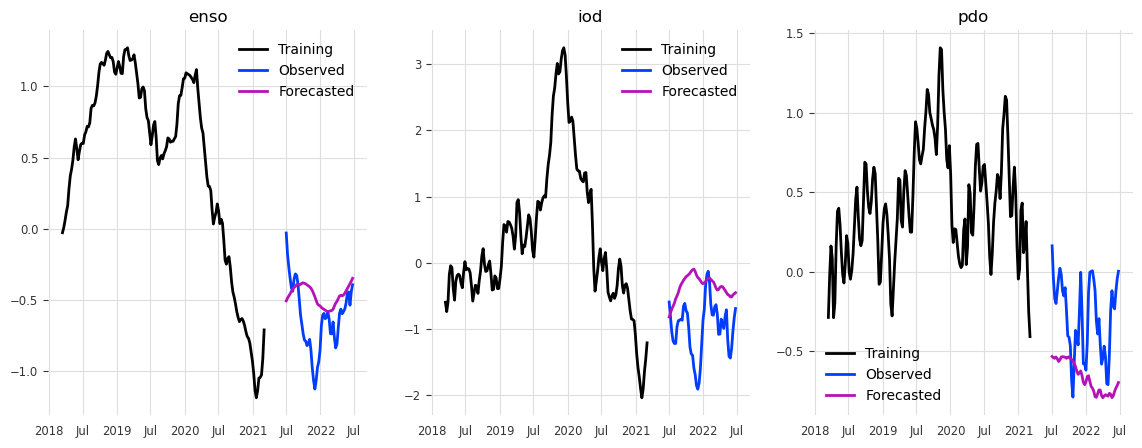

In [28]:
plot_mv_series(sst_val_ts_1, sst_preds_ts_1, (1,3), sst_val_cols, 14, 5, train_ts = sst_train_ts_1, train_ts_length = 156)